# Comparing the Snowdon Beetle SDMs: Logistic Regression, MaxEnt and Random Forest

*Section 11 — Case study: species distribution modelling, notebook 5 of 5.* Previous: `04_random_forest_species_distribution_modelling`. Next: `12_downloading_data/01_dwnld_usgs_landsat_scenes`.

Notebooks 02–04 modelled the Snowdon beetle with three methods that span the range of SDM approaches: a **logistic regression** (a regression model with terms we chose: one per variable, plus a quadratic temperature term), **MaxEnt** (a regularised point-process model that builds its own features: here 20 quadratic and hinge features) and a **random forest** (a machine-learning ensemble of trees that finds its own response shapes and interactions). All three were fitted to **the same** 23 training presences and 7000 background points, with the same seven variables, tuned with the same spatial cross-validation (5 folds of 1 km blocks, repeated on five block grids) and the same selection rule (within one paired standard error of the best AUC, then the highest out-of-fold Boyce index), and evaluated on the same 11 test presences and 3000 test background points. So the differences between them come from the models, not from the data.

This notebook asks: how do the three results differ, why, and what do they agree on about the beetle's niche?

**You will learn:**
- how to compare SDMs fairly when their outputs are on different scales (rank-based accuracy measures, rank correlation of the maps, responses scaled to their maximum);
- how to combine models into a consensus map;
- how the structure of each model (fixed terms, features, trees) shapes its responses, its variable importance and its projections.

**Before you start:** run notebooks `01_prepare_datasets` to `04_random_forest_species_distribution_modelling`; this notebook only reads their outputs.

**Data:** `outputs/sdm_LogReg_outs/`, `outputs/sdm_MaxEnt_outs/` and `outputs/sdm_RF_outs/` (test scores, cross-validation scores, response curves, variable importance, scenarios and maps), `outputs/valid_mask.tif` and `outputs/Chrysolina_cerealis_presences.gpkg`.

**Run time:** less than 1 minute.

## Import Modules and Define the Models

In [1]:
import importlib.util
import os

import geopandas
import matplotlib.pyplot as plt
import numpy
import pandas
import rasterio
import rsgispy
import rsgispy.imagecalc.maths
import rsgispy.imageutils.colourtable
import rsgispy.mapping.raster
import rsgispy.modelling.species_distribution as species_distribution
import rsgispy.tools.jsonio

%matplotlib inline
pandas.set_option("display.max_columns", None)
pandas.set_option("display.width", 200)

out_dir = "outputs/sdm_comparison"
os.makedirs(out_dir, exist_ok=True)
valid_msk_img = "outputs/valid_mask.tif"
presences_gdf = geopandas.read_file("outputs/Chrysolina_cerealis_presences.gpkg", layer="presences")

# Name: (output directory, file prefix, plot colour)
models = {
    "Logistic regression": ("outputs/sdm_LogReg_outs", "lr", "tab:blue"),
    "MaxEnt": ("outputs/sdm_MaxEnt_outs", "maxent", "tab:orange"),
    "Random forest": ("outputs/sdm_RF_outs", "rf", "tab:green"),
}
train_gdf = geopandas.read_file("outputs/sdm_LogReg_outs/sdm_train.gpkg", layer="train")
train_pres_gdf = train_gdf[train_gdf["clsid"] == 1]
analysis_vars = [
    "calc_grass_dist", "flush_dist", "impr_grass_dist", "ledges_dist",
    "rock_dist", "scree_dist", "winter_temp",
]

## 1. Accuracy

AUC, TSS (each model at its own maximum-TSS threshold) and the Boyce index depend only on how each model **ranks** the samples, so they can be compared although the three outputs are on different scales (balanced probabilities, cloglog, and the fraction of trees voting presence). The table gathers, for each model: the single model's test scores and its null-model 95th percentile, the test scores of the five-member spatial ensemble, and the mean out-of-fold (spatial cross-validation) scores, with the training AUC of the ensemble members for comparison.

,Logistic regression,MaxEnt,Random forest
test AUC (single),0.962,0.987,0.981
test TSS (single),0.875,0.940,0.918
test Boyce (single),0.896,0.768,0.427
null AUC 95th pct,0.674,0.654,0.671
test AUC (ensemble),0.964,0.987,0.980
test TSS (ensemble),0.886,0.939,0.906
test Boyce (ensemble),0.944,0.773,0.206
train AUC (CV members),0.961,0.979,0.990
spatial CV AUC,0.932,0.933,0.935
spatial CV AUC (sd),0.044,0.048,0.046


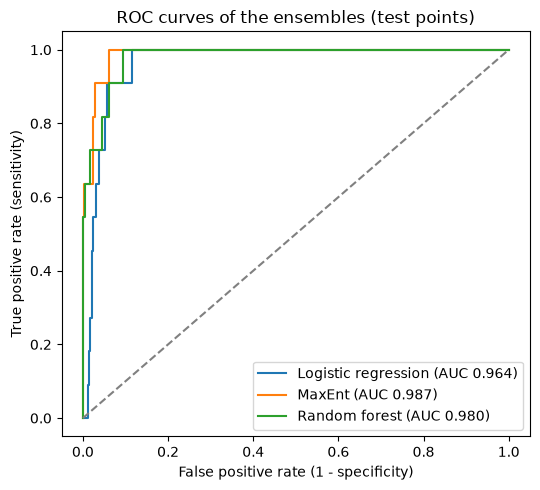

In [2]:
acc_rows = {}
ens_scores = {}
for name, (mdl_dir, prefix, _) in models.items():
    single = rsgispy.tools.jsonio.read_json_to_dict(os.path.join(mdl_dir, f"{prefix}_test_metrics.json"))
    test_df = pandas.read_csv(os.path.join(mdl_dir, f"{prefix}_test_scores.csv"))
    ens_scores[name] = test_df
    ens = species_distribution.calc_sdm_eval_metrics(test_df["clsid"], test_df["ens_prob"], bg_scores="absences")
    cv_df = pandas.read_csv(os.path.join(mdl_dir, f"{prefix}_spatial_cv_scores.csv"))
    acc_rows[name] = {
        "test AUC (single)": single["auc"],
        "test TSS (single)": single["tss"],
        "test Boyce (single)": single["boyce"],
        "null AUC 95th pct": single["null_p95"],
        "test AUC (ensemble)": ens["auc"],
        "test TSS (ensemble)": ens["tss"],
        "test Boyce (ensemble)": ens["boyce"],
        "train AUC (CV members)": cv_df["train_auc"].mean(),
        "spatial CV AUC": cv_df["val_auc"].mean(),
        "spatial CV AUC (sd)": cv_df["val_auc"].std(),
        "spatial CV TSS": cv_df["val_tss"].mean(),
        "spatial CV Boyce": cv_df["val_boyce"].mean(),
    }
acc_df = pandas.DataFrame(acc_rows)
acc_df.to_csv(os.path.join(out_dir, "accuracy_comparison.csv"))

fig, ax = plt.subplots(figsize=(5.5, 5))
for name, test_df in ens_scores.items():
    fpr, tpr, auc = species_distribution.calc_binary_roc_auc(test_df["clsid"], test_df["ens_prob"])
    ax.plot(fpr, tpr, color=models[name][2], label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], color="grey", ls="--")
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("ROC curves of the ensembles (test points)")
ax.legend(loc="lower right")
fig.tight_layout()
acc_df.round(3)

**All three models found a real signal.** Every model's test AUC (0.96–0.99) is far above the 95th percentile of its null models (0.65–0.67).

**The models are indistinguishable in spatial cross-validation.** All three have a mean out-of-fold AUC of 0.93 (0.932, 0.933 and 0.935) with the same spread between folds (sd 0.044–0.048), and TSS of 0.86–0.87. On the randomly chosen test points, the two flexible models score higher (MaxEnt 0.987, random forest 0.981, against 0.962 for the logistic regression): the classic signature of flexible models with few, clustered presences, rewarded for interpolating between nearby training sites. In spatial cross-validation, which tests prediction at sites the model has not seen, that advantage disappears. The flexible models also fit their training data more closely (training AUC of the CV members 0.979 and 0.990, against 0.961).

**Ranking within the suitable area** (Boyce index) separates the models most. On the test points the logistic regression is best (0.90 single, 0.94 ensemble), MaxEnt is good (0.77), and the random forest poor (0.43 single, 0.21 ensemble: a plateau of similar values over the suitable area). In spatial cross-validation the order is reversed (0.33 for the logistic regression, 0.60 for the other two), but the out-of-fold Boyce indices come from 3–9 presences per fold and vary enormously between folds (the logistic regression's range from −0.42 to 0.94).

**The differences are small relative to the uncertainty.** With 11 test presences and five folds, differences of about 0.01–0.02 in AUC are not meaningful, and the Boyce indices of single folds or of 11 test presences are noisier still. What is robust is that none of the three models predicts new sites clearly better than the others; they differ in *how* they predict (section 3), not in how well.

## 2. The Maps

### 2.1 Continuous Suitability

The three maps are on different scales, so we compare them by **rank**: the Spearman correlation between each pair of maps over all the valid pixels.

,Logistic regression,MaxEnt,Random forest
Logistic regression,1.000,0.864,0.752
MaxEnt,0.864,1.000,0.713
Random forest,0.752,0.713,1.000


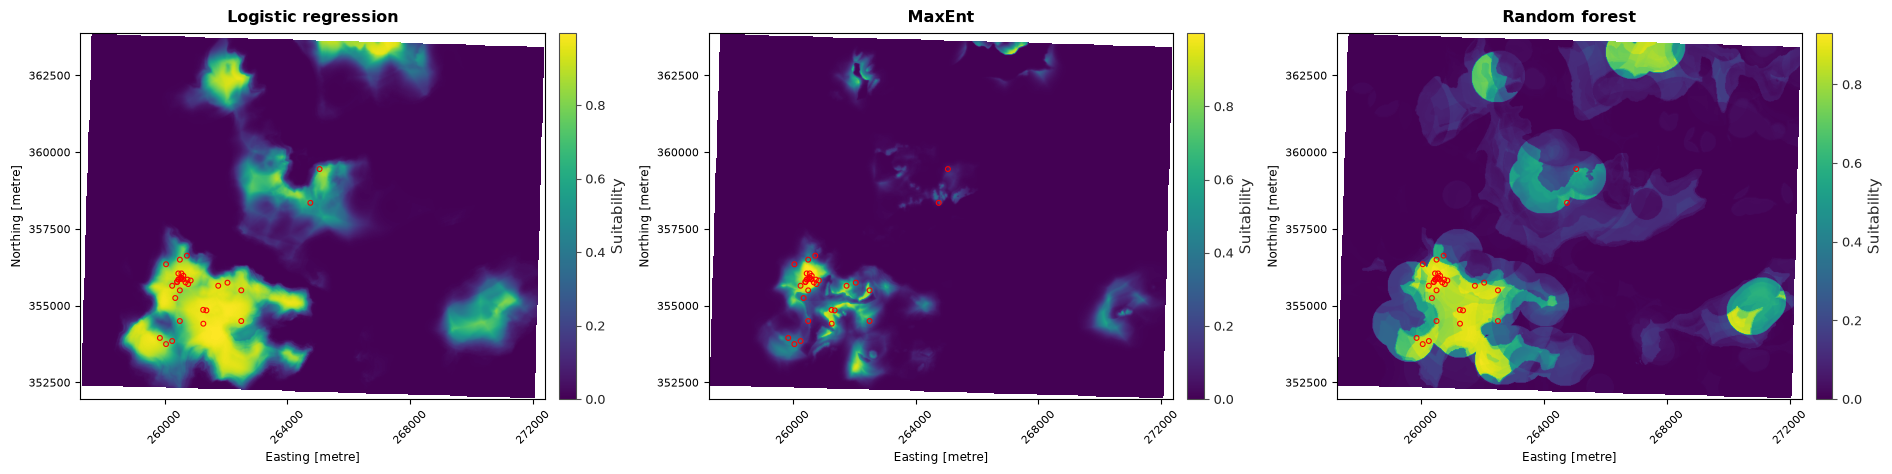

In [3]:
prob_arrs = dict()
for name, (mdl_dir, prefix, _) in models.items():
    with rasterio.open(os.path.join(mdl_dir, f"Snowdon_Beetle_{prefix}_sdm_prob.tif")) as src:
        prob_arrs[name] = src.read(1)
        pxl_km2 = abs(src.res[0] * src.res[1]) / 1e6
valid = numpy.all([arr >= 0 for arr in prob_arrs.values()], axis=0)
rank_corr_df = pandas.DataFrame({name: arr[valid] for name, arr in prob_arrs.items()}).corr(method="spearman")

fig, axs = plt.subplots(1, 3, figsize=(19, 5))
for ax, (name, (mdl_dir, prefix, _)) in zip(axs, models.items()):
    rsgispy.mapping.raster.create_raster_cmap_img_map(
        ax, input_img=os.path.join(mdl_dir, f"Snowdon_Beetle_{prefix}_sdm_prob.tif"), img_band=1,
        title_str=name, show_colour_bar=True, cbar_label="Suitability", show_scale_bar=False,
    )
    presences_gdf.plot(ax=ax, facecolor="none", edgecolor="red", markersize=12, linewidth=0.8)
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
rank_corr_df.round(3)

The logistic regression and MaxEnt maps are similar in rank (Spearman r = 0.86): both are smooth functions of the same variables, with similar ledge and temperature responses, although MaxEnt's map is more concentrated. The random forest's map is less similar to either (r = 0.75 and 0.71): its step responses produce sharp, often circular edges and patchier suitability, and it ranks the large unsuitable part of the study area differently (the order among low values, which dominate the pixel count, depends on its steps).

### 2.2 Suitable Habitat and a Consensus Map

Each model's map was thresholded at its own maximum-TSS threshold (notebooks 02–04). Adding the three binary maps gives a simple **consensus** (committee) map: the number of models (0–3) that predict each pixel suitable. Combining several models is common practice in SDM: where they agree, the prediction does not depend on the choice of model; where they disagree, it does, and that uncertainty should be reported.

,map,threshold,suitable area (km²)
0,Logistic regression,0.550,18.908
1,MaxEnt,0.174,10.267
2,Random forest,0.482,16.582
3,Consensus: No model,NaN,147.436
4,Consensus: 1 model,NaN,8.014
5,Consensus: 2 models,NaN,6.446
6,Consensus: All 3 models,NaN,8.284


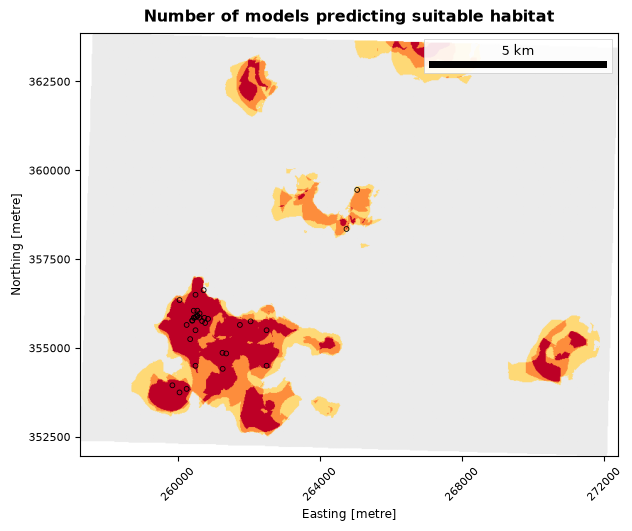

In [4]:
bin_imgs = {
    name: os.path.join(mdl_dir, f"Snowdon_Beetle_{prefix}_sdm_bin.tif")
    for name, (mdl_dir, prefix, _) in models.items()
}
consensus_img = os.path.join(out_dir, "sdm_consensus.tif")
rsgispy.imagecalc.maths.band_maths(
    consensus_img,
    "lr == 255 ? 0 : 1 + lr + mx + rf",
    [rsgispy.imagecalc.maths.BandDefn("lr", bin_imgs["Logistic regression"], 1),
     rsgispy.imagecalc.maths.BandDefn("mx", bin_imgs["MaxEnt"], 1),
     rsgispy.imagecalc.maths.BandDefn("rf", bin_imgs["Random forest"], 1)],
    gdalformat="GTIFF", datatype=rsgispy.TYPE_8UINT, no_data_val=0, use_pbar=False,
)
consensus_classes = {
    1: ("No model", [235, 235, 235]),
    2: ("1 model", [254, 217, 118]),
    3: ("2 models", [253, 141, 60]),
    4: ("All 3 models", [189, 0, 38]),
}
rsgispy.imageutils.colourtable.set_thematic_classes(consensus_img, consensus_classes)

area_rows = []
for name, bin_img in bin_imgs.items():
    with rasterio.open(bin_img) as src:
        bin_arr = src.read(1)
    thres = rsgispy.tools.jsonio.read_json_to_dict(
        os.path.join(models[name][0], f"{models[name][1]}_thresholds.json")
    )["max TSS"]
    area_rows.append({"map": name, "threshold": thres, "suitable area (km²)": (bin_arr == 1).sum() * pxl_km2})
with rasterio.open(consensus_img) as src:
    cons_arr = src.read(1)
for val, (label, _) in consensus_classes.items():
    area_rows.append({"map": f"Consensus: {label}", "suitable area (km²)": (cons_arr == val).sum() * pxl_km2})
area_df = pandas.DataFrame(area_rows)

fig, ax = plt.subplots(figsize=(8, 5.5))
rsgispy.mapping.raster.create_thematic_raster_map(
    ax, input_img=consensus_img, title_str="Number of models predicting suitable habitat"
)
presences_gdf.plot(ax=ax, facecolor="none", edgecolor="black", markersize=12, linewidth=0.6)
ax.tick_params(axis="x", labelrotation=45)
area_df.round(3)

The models predict between 10.3 km² (MaxEnt) and 18.9 km² (logistic regression) of suitable habitat, 6–11 % of the study area. The differences in area come partly from the models and partly from the thresholds (each chosen on 11 test presences; the logistic regression's 10th percentile training presence threshold, for example, would give 13.3 km²).

All three models agree on 8.3 km², mainly around the cluster of records on Yr Wyddfa and the high ground to its south and east, with smaller cores in the northern and eastern patches. A further 6.4 km² is predicted by two models and 8.0 km² by only one, mostly around the edges of these cores and in the central patch around the two isolated records. For a conservation application, the core predicted by all three models is the robust result; the fringes and outlying patches are hypotheses, the natural targets of a survey.

## 3. The Responses

Each model's response curve (from notebooks 02–04, with the other variables held at their mean at the training presences) is divided by its own maximum, so the **shapes** can be compared.

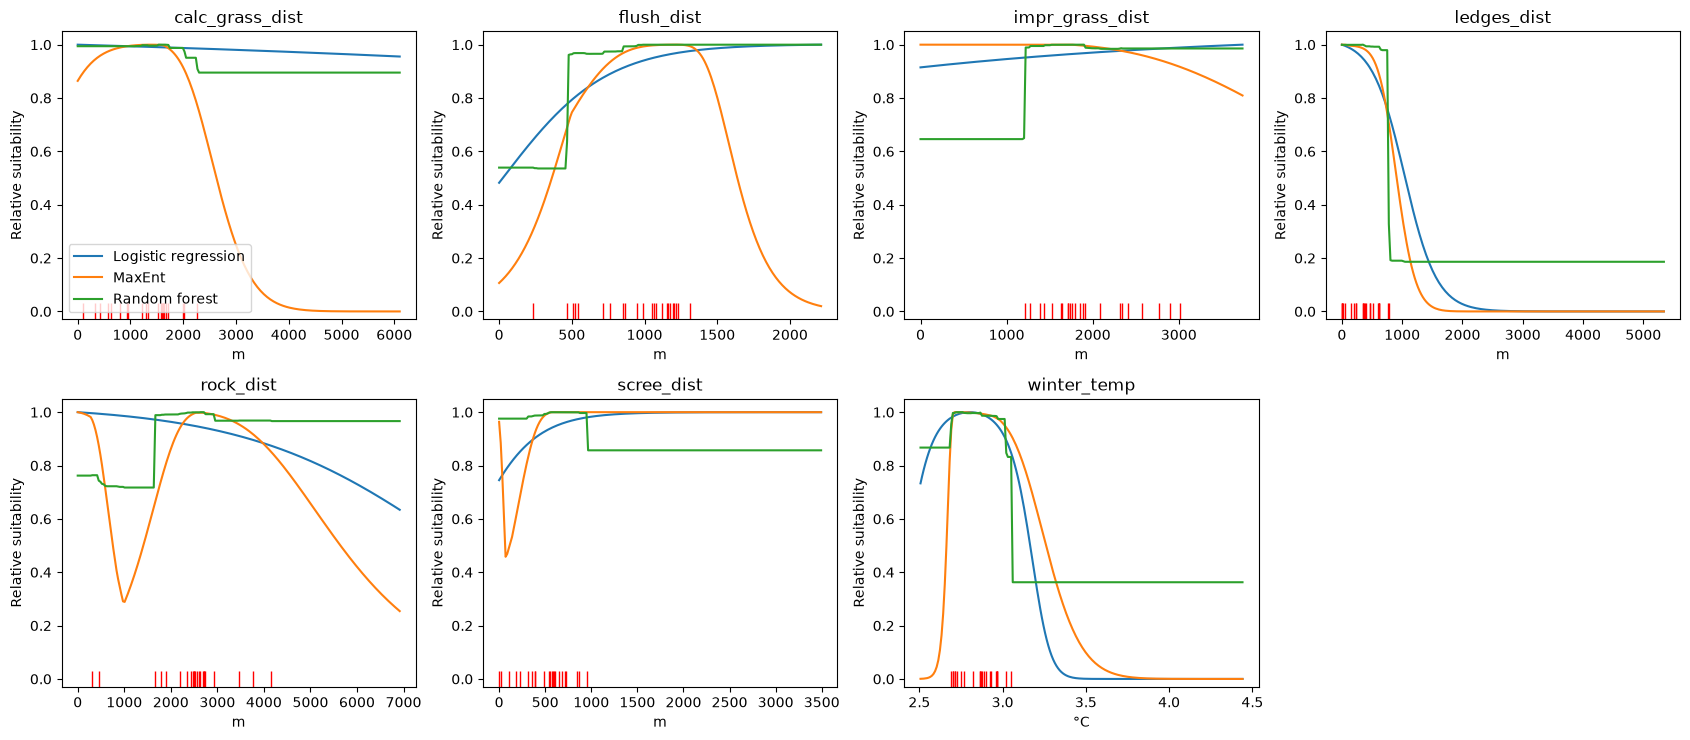

In [5]:
resp_dfs = {
    name: pandas.read_csv(os.path.join(mdl_dir, f"{prefix}_response_curves.csv"))
    for name, (mdl_dir, prefix, _) in models.items()
}
units = {"winter_temp": "°C"}
fig, axs = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, var_name in zip(axs.flatten(), analysis_vars):
    for name, resp_df in resp_dfs.items():
        resp = resp_df[f"{var_name}_resp"]
        ax.plot(resp_df[f"{var_name}_vals"], resp / resp.max(), color=models[name][2], label=name)
    ax.plot(train_pres_gdf[var_name], numpy.zeros(len(train_pres_gdf)), "|", color="red", ms=12)
    ax.set_ylim(-0.03, 1.05)
    ax.set_title(var_name)
    ax.set_xlabel(units.get(var_name, "m"))
    ax.set_ylabel("Relative suitability")
axs[0, 0].legend(loc="lower left")
axs.flatten()[-1].axis("off")
fig.tight_layout()

Where the models agree, the result is robust to the choice of model:

* **Distance to species-rich ledges** — all three put the beetle within about 750–1000 m of a ledge. The logistic regression declines smoothly over 500–2000 m, MaxEnt more steeply over 500–1500 m; the random forest drops abruptly at about 780 m, just beyond the furthest training presence.
* **Winter temperature** — all three have the peak at the cold end (2.7–2.8 °C, roughly 700–750 m in this study area). On the warm side, the logistic regression falls steeply and reaches 0 by about 3.4 °C; MaxEnt falls a little more gradually; the random forest drops to a floor of about a third of its maximum at 3.05 °C (the warmest training presence) and stays there. On the cold side they disagree: MaxEnt drops to 0 below the coldest presence (2.69 °C), the logistic regression declines gently, and the random forest steps down only a little.
* **Distance to flushes** — all three: less suitable close to flushes.

Where they disagree, it is because of the models' structure and the flexibility allowed by the tuning, not the data:

* the logistic regression's terms are fixed in shape (S-curves on the log-odds scale, a parabola for temperature), so it extends every trend smoothly, including the implausible rise away from scree caused by collinearity;
* MaxEnt, with 20 weakly regularised hinge and quadratic features, draws responses around the presences: suitability falls again beyond 1.5 km from a flush and beyond 2.5 km from calcareous grassland, and dips 1 km from rock, where there are no presences;
* the random forest's steps follow the edges of the presence data in every variable, creating responses such as the drop within 1.2 km of improved grassland that have no ecological basis.

The two flexible models both learn an envelope around the 23 presences, MaxEnt with smooth curves and the forest with steps; the logistic regression, with the terms we chose, cannot.

## 4. Variable Importance

Three views of importance for each model: the jackknife (test AUC with the variable alone, and the drop in test AUC when it is left out), the total-order Sobol index, and the **rank** of the mean |SHAP| value (ranks, because the SHAP values are on different scales: log-odds for the logistic regression, probabilities for the others; for the logistic regression the interventional SHAP values of temperature and its square are added together).

In [6]:
imp_frames = []
for name, (mdl_dir, prefix, _) in models.items():
    metrics = rsgispy.tools.jsonio.read_json_to_dict(os.path.join(mdl_dir, f"{prefix}_test_metrics.json"))
    jk_df = pandas.read_csv(os.path.join(mdl_dir, f"{prefix}_jackknife_var_importance.csv"), index_col=0)
    imp = pandas.DataFrame(
        {
            "AUC alone": jk_df["roc_test_acc_only_var"],
            "AUC drop if left out": metrics["auc"] - jk_df["roc_test_acc_leave_var_out"],
        }
    )
    # Written by salib_sklearn_mdl_sensitivity: the first column is "variable".
    sobol_csv = os.path.join(mdl_dir, f"{prefix}_sobol_total.csv")
    if os.path.exists(sobol_csv):
        imp["Sobol ST"] = pandas.read_csv(sobol_csv, index_col="variable")["ST"]
    shap_csv = os.path.join(mdl_dir, f"{prefix}_shap_mean_abs.csv")
    if os.path.exists(shap_csv):
        shap_df = pandas.read_csv(shap_csv, index_col=0)
        if prefix == "lr":
            shap_vals = shap_df["interventional"].drop("winter_temp_sq")
            shap_vals["winter_temp"] += shap_df.loc["winter_temp_sq", "interventional"]
        else:
            shap_vals = shap_df["mean_abs_shap"]
        imp["SHAP rank"] = shap_vals.rank(ascending=False)
    imp.columns = pandas.MultiIndex.from_product([[name], imp.columns])
    imp_frames.append(imp)
imp_df = pandas.concat(imp_frames, axis=1).loc[analysis_vars]
imp_df.to_csv(os.path.join(out_dir, "importance_comparison.csv"))
imp_df.round(3)

Logistic regression                                            MaxEnt                                         Random forest                                        
                          AUC alone AUC drop if left out Sobol ST SHAP rank AUC alone AUC drop if left out Sobol ST SHAP rank     AUC alone AUC drop if left out Sobol ST SHAP rank
calc_grass_dist               0.470                0.000    0.001       7.0     0.833                0.002    0.487       6.0         0.509                0.001    0.007       7.0
flush_dist                    0.889                0.016    0.095       4.0     0.919                0.011    0.502       3.0         0.863                0.008    0.039       3.0
impr_grass_dist               0.737               -0.002    0.004       6.0     0.789                0.000    0.020       7.0         0.763               -0.002    0.046       4.0
ledges_dist                   0.893                0.020    0.607       2.0     0.899                0.012    1.284       1.0         0.893                0.013    0.799       1.0
rock_dist                     0.655               -0.004    0.023       5.0     0.845                0.001    0.179       4.0         0.755               -0.002    0.017       5.0
scree_dist                    0.597                0.004    0.236       3.0     0.779                0.002    0.135       5.0         0.679                0.002    0.006       6.0
winter_temp                   0.859                0.011    0.657       1.0     0.865                0.001    0.433       2.0         0.850                0.005    0.332       2.0

**The models agree on what matters.** In all three, the distance to species-rich ledges has the top SHAP rank and is among the two largest Sobol indices, winter temperature has the second SHAP rank, and the distance to flushes comes third or fourth. Leaving out ledges or flushes causes the largest drops in test AUC in every model.

**The differences are about how each model handles the weaker and correlated variables:**

* the logistic regression gives scree a large Sobol index (0.24) and the third SHAP rank, the effect of its collinearity with ledges (an artefact, discussed in notebook 02); calcareous grassland carries no information in it (AUC alone 0.47);
* the 20-feature MaxEnt model makes every variable informative on its own (AUC alone 0.78–0.92, including calcareous grassland at 0.83), because a flexible response can fit almost any pattern of 23 presences; its Sobol indices are unreliable (the total index of ledges is above 1, with intervals as large as the indices; notebook 03, section 5.4);
* the random forest spreads small amounts of importance over every variable (Sobol ST 0.01–0.05 for the five weaker ones), because each of them adds a step at the edge of the presence data.

The jackknife "AUC drop if left out" values are all below 0.025 and some are slightly negative: with 11 test presences they mainly show that no single variable other than ledges, flushes and temperature is indispensable.

## 5. Projections to a Warmer Climate

The suitable area under the +0.5 °C and +1 °C scenarios of notebooks 02–04 (each model thresholded at its own current maximum-TSS threshold). Remember that, with this temperature raster, these warmings correspond to large shifts in altitude (notebook 02, section 16), and that 6.6 % and 34 % of the study area are outside the training range in the two scenarios: the projections are a comparison of how the models **extrapolate**, not forecasts.

In [7]:
scen_frames = []
for name, (mdl_dir, prefix, _) in models.items():
    scen_df = pandas.read_csv(os.path.join(mdl_dir, f"{prefix}_scenarios.csv"))
    scen_df.insert(0, "model", name)
    scen_frames.append(scen_df[["model", "warming (°C)", "current (km²)", "scenario (km²)",
                                "stable (km²)", "gained (km²)", "net change (%)"]])
pandas.concat(scen_frames).round(2)

,model,warming (°C),current (km²),scenario (km²),stable (km²),gained (km²),net change (%)
0,Logistic regression,0.5,18.91,2.13,1.79,0.33,-88.75
1,Logistic regression,1.0,18.91,0.00,0.00,0.00,-100.00
0,MaxEnt,0.5,10.27,3.73,2.12,1.61,-63.71
1,MaxEnt,1.0,10.27,0.00,0.00,0.00,-100.00
0,Random forest,0.5,16.58,1.18,1.18,0.00,-92.88
1,Random forest,1.0,16.58,0.00,0.00,0.00,-100.00


At +0.5 °C the logistic regression and the random forest lose about 90 % of their suitable area (−89 % and −93 %), remaining only on the highest ground; MaxEnt loses less (−64 %), because it gains 1.6 km² on the coldest summits. At +1 °C none of the models keeps any suitable area.

The differences come from how the models treat temperatures outside those of the presences. On the warm side, the logistic regression's parabola and MaxEnt's quadratic and hinge features keep falling, and the random forest's response drops to a floor (a third of its maximum) that is below its threshold, so for all three, warmer than the presences means unsuitable. On the cold side they differ: MaxEnt considers everything colder than the coldest presence (2.69 °C) unsuitable today, so warming *creates* suitable ground on the summits; the logistic regression and the random forest already consider that ground fairly suitable, so it adds little. Neither behaviour is "correct": the data contain no presences colder than 2.69 °C or warmer than 3.05 °C, so the projections differ in **assumptions**, not in evidence. This is why projections should be made with several models, reported with their disagreement, and accompanied by MESS/ExDet maps showing where they extrapolate.

## 6. Summary: Why Do the Models Differ, and What Do They Agree On?

**What the three models agree on: the beetle's niche.** With the same data, three very different methods describe the same core of the niche: the Snowdon beetle is found **within about 1 km of upland species-rich ledges**, in a **narrow, cool band of winter temperature** at the cold end of the study area (the training presences span 2.69–3.05 °C, roughly 550–750 m in this temperature raster, within the 555–827 m of the NRW surveys), and **away from wet flushes**. Because the three models agree on these, the conclusions do not depend on the choice of model; their limits come from the data (34 presences from a few crags, proxies for thyme and grazing, temperature confounded with altitude), as discussed in notebook 02. Beyond these three variables, the models disagree, and the flexible ones fit patterns that are more likely to be properties of 23 presences than of the beetle.

**Why the results differ.** The data were identical, so the differences come from each model's assumptions about the **shape** of the responses, and from how much flexibility the tuning allowed:

| | Logistic regression | MaxEnt | Random forest |
| --- | --- | --- | --- |
| Response shapes | Chosen by us: S-curves, plus a parabola for temperature | Built from features (here 20 quadratic and hinge features), weakly regularised | Learnt freely: steps |
| Weak variables | Kept, with small coefficients (L1 can remove them) | All used, with non-monotonic responses | Each used a little |
| Collinearity | Can produce implausible signs (scree) | Shared between flexible responses | Absorbed (importance shared) |
| Fit to the training sites | Smooth | Close: an envelope of smooth curves around the presences | Close: an envelope of steps around the presences |
| Spatial CV AUC | 0.93 | 0.93 | 0.94 |
| Test Boyce index (ensemble) | 0.94 | 0.77 | 0.21 |
| Beyond the presences' range | Extrapolates the trends (parabola keeps falling) | Clamps the variables beyond the training range; within it, falls steeply on both sides of the presences | Flat (constant at the last step) |
| Output | Relative suitability (balanced classes) | Cloglog | Fraction of trees (balanced classes) |

**How the tuning shaped the models.** All three were tuned the same way: the settings within one paired standard error of the best spatial cross-validated AUC, then the highest out-of-fold Boyce index. With 23 presences, the AUC could not separate simple from flexible settings, and the Boyce index, estimated from 3–9 presences per fold, chose a moderately regularised logistic regression, the *least* regularised MaxEnt and a forest with large (100-sample) leaves. The more traditional rule (the simplest accepted setting) would have chosen a slightly more regularised logistic regression (`C` = 0.1 with an L1 penalty), a 3-coefficient linear MaxEnt and a forest with 300-sample leaves; AICc would have chosen a 10-feature MaxEnt. With so few presences, **the tuning rule matters as much as the model**: look at the response curves of the selected model before you trust it, and try the alternatives.

**Which should you use?**

* With **few, clustered presences**, as here, the constrained model (the logistic regression with carefully chosen terms) gives the smoothest, most interpretable responses and the best ranking within the suitable area, and transfers to new blocks as well as the flexible models. MaxEnt can do the same with stronger regularisation (fewer features); it chooses its own response shapes with less hand-crafting (we had to add the quadratic temperature term to the logistic regression ourselves), and it is designed for presence–background data, but its flexibility needs to be held in check.
* A **random forest** comes into its own with many presences, many variables and genuine interactions; with 23 training presences it mostly learns an envelope around them. If you use one, tune it with spatial cross-validation, check more than one accuracy measure, and never set its threshold from its training predictions.
* For **projections** to other conditions, model choice changes the answer wherever the model extrapolates, so use several models and report where they disagree, together with MESS/ExDet.

**Using them together.** Fitting several models and combining them, as in the consensus map of section 2.2 (or by averaging their rank-transformed predictions), is common practice in SDM (e.g. "ensemble forecasting", Araújo & New 2007). The areas where all the models agree are robust to the choice of model; the areas where they disagree show the uncertainty that comes from that choice, and they deserve to be reported, not hidden.

**Going further:** try the other options of the guide (bias grids if target-group records are available, `thin_pts_min_dist` to thin the presences further, `SpatialBufferCV` or `nested_spatial_cv`), add the habitats hidden in Phase 1 mosaics (notebook 01), try the alternative tuning choices above, or repeat the comparison with the stricter record filters of notebook 01 and see which conclusions survive.